> **Revision (November 2026).** Re-run end to end on the local data files, with three corrections:
> 1. **Call minutes are rounded up per call**, as Megaline bills. The original code converted to whole numbers
>    *before* rounding up (`np.ceil(duration.astype(int))`), which cut the decimals, so a 2.3-minute call counted as 2.
> 2. **Data is billed per whole GB of the monthly total.** Sessions are no longer rounded; each month's total is rounded
>    up to whole gigabytes and extra data is charged per GB, as Megaline's rules state.
> 3. **Plans are compared per customer**, not only on totals: Surf has 339 customers and Ultimate 161, so totals mostly
>    reflect the number of customers. The NY-NJ test is also repeated with each customer counted once.
>
> The average Surf bill moves from \$57.10 to \$60.71; the conclusion that Ultimate earns more per customer holds.
> The regional difference does not survive counting each customer once. The conclusion is updated to match.

# purpose of the project
In this project we are going to analyse the users usage criteria for calls, messages and internet used. We will be able to find insights which will be useful for the telecom company to manage their future policies especially regarding thier vailable user plans.

Our methodology for this project is based on **following objectives**:
- Preprocessing of data including fixes the observed issues in the data like data types and missing values
- Perform analysis on the individual dataframes to create our own analytical dataframes and then used them to findout hidden insights in the data
- In the nd we will perform hypothesis testing to answere the question based on user plan avilable for this company.



---



#Initialization

In [1]:
# importing all the required libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns



---



#Load data

In [2]:
# Loading the data into pandas dataframes from this project folder
calls = pd.read_csv('megaline_calls.csv')
internet = pd.read_csv('megaline_internet.csv')
messages = pd.read_csv('megaline_messages.csv')
plans = pd.read_csv('megaline_plans.csv')
users = pd.read_csv('megaline_users.csv')



---



#Data Assessing

##1.Plans

In [3]:
plans.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


In [4]:
plans.shape

(2, 8)

In [5]:
plans.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      str    
dtypes: float64(2), int64(5), str(1)
memory usage: 260.0 bytes


In [6]:
plans.describe()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
count,2.000000,2.000000,2.000000,2.000000,2.00000,2.000000,2.000000
mean,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
std,671.751442,10861.160159,1767.766953,35.355339,2.12132,0.014142,0.014142
min,50.000000,15360.000000,500.000000,20.000000,7.00000,0.010000,0.010000
25%,287.500000,19200.000000,1125.000000,32.500000,7.75000,0.015000,0.015000
50%,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
75%,762.500000,26880.000000,2375.000000,57.500000,9.25000,0.025000,0.025000
max,1000.000000,30720.000000,3000.000000,70.000000,10.00000,0.030000,0.030000


##Observations from plans dataset
- There are two plans for the customers offered by magaline company including surf and ultimate. The surf plan is small but the ultimate plans offers large voulume of package.
- There is no mistake in the dataset but a slight confusion regarding these column name:
      usd_per_gb	usd_per_message	usd_per_minute
  There should be a mentioning of extra payment which a user has to paid after he/she consumed the provided volume of the respective package.

##Fix data

- No data cleaning issue as the data is very precise here in plans csv file. It doesnot contains any data tyes mistakes or any missing data or duplicated rows problem.

##Enrich data

In [7]:
# Converting mb's into GB's for user readability
plans['gb_per_month_included'] = plans['mb_per_month_included']/1024
plans.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15.0
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0


**Reason for converting mbs into gbs**
- To mae it more user readable.



---



---



##2.Users

In [8]:
users.sample(10)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
111,1111,Booker,Hahn,75,"Urban Honolulu, HI MSA",2018-09-17,surf,NaN
129,1129,Marin,Bolton,70,"Baton Rouge, LA MSA",2018-11-10,surf,2018-12-27
445,1445,Elodia,Donovan,71,"Dallas-Fort Worth-Arlington, TX MSA",2018-01-27,ultimate,NaN
371,1371,Roderick,Slater,27,"Portland-Vancouver-Hillsboro, OR-WA MSA",2018-10-27,surf,NaN
427,1427,Zofia,Brock,64,"Washington-Arlington-Alexandria, DC-VA-MD-WV MSA",2018-01-26,ultimate,NaN
8,1008,Emely,Hoffman,53,"Orlando-Kissimmee-Sanford, FL MSA",2018-08-03,ultimate,NaN
246,1246,Stevie,Moran,69,"Tampa-St. Petersburg-Clearwater, FL MSA",2018-01-09,ultimate,2018-07-31
94,1094,Walter,Petersen,54,"Los Angeles-Long Beach-Anaheim, CA MSA",2018-10-30,surf,2018-12-12
465,1465,Arianna,Morrison,73,"Pittsburgh, PA MSA",2018-06-22,ultimate,NaN
384,1384,Dominique,Good,36,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA",2018-06-09,ultimate,NaN


In [9]:
users.shape

(500, 8)

In [10]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     500 non-null    int64
 1   first_name  500 non-null    str  
 2   last_name   500 non-null    str  
 3   age         500 non-null    int64
 4   city        500 non-null    str  
 5   reg_date    500 non-null    str  
 6   plan        500 non-null    str  
 7   churn_date  34 non-null     str  
dtypes: int64(2), str(6)
memory usage: 31.4 KB


In [11]:
users.describe()

,user_id,age
count,500.000000,500.000000
mean,1249.500000,45.486000
std,144.481833,16.972269
min,1000.000000,18.000000
25%,1124.750000,30.000000
50%,1249.500000,46.000000
75%,1374.250000,61.000000
max,1499.000000,75.000000


##Observations from users dataset
- All the columns are correctly placed except the city column as it contains two important information. It includes both city and state name for the user. We should seperate them into different columns respectively.

- The `churn_date` data is not well explaned. The entries where the data is missing simply represents that the customer is still using the service plan. And where the particular date is mentioned it means the customer has left the service on that particular date.

- The date columns have incorrect data types. These columns should have datetime format.

- The average age of customer is 45 years. The minimum and maximum ages are 18 and 75 respectively.

##Fix data

In [12]:
# Converting date columns into datetime format
users['reg_date'] = pd.to_datetime(users['reg_date'])
users['churn_date'] = pd.to_datetime(users['churn_date'])
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    str           
 2   last_name   500 non-null    str           
 3   age         500 non-null    int64         
 4   city        500 non-null    str           
 5   reg_date    500 non-null    datetime64[us]
 6   plan        500 non-null    str           
 7   churn_date  34 non-null     datetime64[us]
dtypes: datetime64[us](2), int64(2), str(4)
memory usage: 31.4 KB


**Reason for changing date data type?**

Converting the 'call_date' column to datetime format ensures data consistency and enables date-based operations, sorting, and visualization in analyses which would otherwise be impossible to do in case the date is present in string form.

##Data enriching

In [13]:
# splitting the city column into city and state name respectively
city_info=users['city'].str.split(',', expand=True)
users['city'] = city_info[0]
users['state'] = city_info[1]
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,state
0,1000,Anamaria,Bauer,45,Atlanta-Sandy Springs-Roswell,2018-12-24,ultimate,NaT,GA MSA
1,1001,Mickey,Wilkerson,28,Seattle-Tacoma-Bellevue,2018-08-13,surf,NaT,WA MSA
2,1002,Carlee,Hoffman,36,Las Vegas-Henderson-Paradise,2018-10-21,surf,NaT,NV MSA
3,1003,Reynaldo,Jenkins,52,Tulsa,2018-01-28,surf,NaT,OK MSA
4,1004,Leonila,Thompson,40,Seattle-Tacoma-Bellevue,2018-05-23,surf,NaT,WA MSA


**Reason for splitting the city column**

In general it is better to have a single value information in a single column. We have done it because we have to perform the statistical testing based on specific states so we have to extract the states values from it.

In [14]:
# splitting the date column into respective month and days data
users['reg_year'] = users['reg_date'].dt.year
users['reg_month'] = users['reg_date'].dt.month
users['reg_day'] = users['reg_date'].dt.day_name()
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,state,reg_year,reg_month,reg_day
0,1000,Anamaria,Bauer,45,Atlanta-Sandy Springs-Roswell,2018-12-24,ultimate,NaT,GA MSA,2018,12,Monday
1,1001,Mickey,Wilkerson,28,Seattle-Tacoma-Bellevue,2018-08-13,surf,NaT,WA MSA,2018,8,Monday
2,1002,Carlee,Hoffman,36,Las Vegas-Henderson-Paradise,2018-10-21,surf,NaT,NV MSA,2018,10,Sunday
3,1003,Reynaldo,Jenkins,52,Tulsa,2018-01-28,surf,NaT,OK MSA,2018,1,Sunday
4,1004,Leonila,Thompson,40,Seattle-Tacoma-Bellevue,2018-05-23,surf,NaT,WA MSA,2018,5,Wednesday


**Reason for age groups and reg month**

 - Extract the registration year and month from the 'reg_date' column. This can be useful for tracking user registration trends over time.
 - Categorize users into age groups (e.g.,adult and aged.). This can help in understanding the distribution of users across different age groups.

In [15]:
users['age_category'] = pd.cut(users['age'], bins=[18, 60, float('inf')], labels=['adult', 'aged'], right=False)
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,state,reg_year,reg_month,reg_day,age_category
0,1000,Anamaria,Bauer,45,Atlanta-Sandy Springs-Roswell,2018-12-24,ultimate,NaT,GA MSA,2018,12,Monday,adult
1,1001,Mickey,Wilkerson,28,Seattle-Tacoma-Bellevue,2018-08-13,surf,NaT,WA MSA,2018,8,Monday,adult
2,1002,Carlee,Hoffman,36,Las Vegas-Henderson-Paradise,2018-10-21,surf,NaT,NV MSA,2018,10,Sunday,adult
3,1003,Reynaldo,Jenkins,52,Tulsa,2018-01-28,surf,NaT,OK MSA,2018,1,Sunday,adult
4,1004,Leonila,Thompson,40,Seattle-Tacoma-Bellevue,2018-05-23,surf,NaT,WA MSA,2018,5,Wednesday,adult


**What do we need age segmentation for?**

**Marketing Targeting:** Age segmentation helps tailor marketing efforts for each plan based on age group preferences and responsiveness to advertising messages.

**Product Customization:** It allows customization of plan features, pricing, and add-ons to match the specific needs and budgets of different age groups.

**Churn Analysis:** By understanding age-specific churn patterns, it enables adjustments to improve customer retention strategies.

**Revenue Maximization:** It aids in optimizing pricing and service offerings to maximize revenue, considering how different age groups use telecom services.

**Demographic Insights:** Combined with other demographic data like location, it provides a comprehensive view of the customer base for informed business decisions and market expansion.



---



---



##3.Calls

In [16]:
calls.head()

,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,8.52
1,1000_145,1000,2018-12-27,13.66
2,1000_247,1000,2018-12-27,14.48
3,1000_309,1000,2018-12-28,5.76
4,1000_380,1000,2018-12-30,4.22


In [17]:
calls.shape

(137735, 4)

In [18]:
calls.info()

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  str    
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  str    
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 4.2 MB


In [19]:
calls.describe()

,user_id,duration
count,137735.000000,137735.000000
mean,1247.658046,6.745927
std,139.416268,5.839241
min,1000.000000,0.000000
25%,1128.000000,1.290000
50%,1247.000000,5.980000
75%,1365.000000,10.690000
max,1499.000000,37.600000


In [20]:
calls.isna().sum()

id           0
user_id      0
call_date    0
duration     0
dtype: int64

##Observations from calls dataframe
- All the data-types are correct except the call-date column. We can chnage it into date time format.
- No missing value in any column.
- The mean duration call for all the customers is 7.74min with the min and max values are 0.00 and 37.6min respectively. The min value of 0.00 can be represented as drop calls.

##Fix data

In [21]:
calls['call_date'] = pd.to_datetime(calls['call_date'])
calls.info()

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  str           
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[us]
 3   duration   137735 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 4.2 MB


**Reason for changing date data type?**

Converting the 'call_date' column to datetime format ensures data consistency and enables date-based operations, sorting, and visualization in analyses which would otherwise be impossible to do in case the date is present in string form.

##Data enriching

In [22]:
# splitting the date column into respective year, month and days data

# 1. Call year
calls['call_year'] = pd.to_datetime(calls['call_date']).dt.year

# 1. Call Month
calls['month'] = pd.to_datetime(calls['call_date']).dt.month

# 2. Call Day of the Week
calls['call_day_of_week'] = pd.to_datetime(calls['call_date']).dt.day_name()

calls.head()

,id,user_id,call_date,duration,call_year,month,call_day_of_week
0,1000_93,1000,2018-12-27,8.52,2018,12,Thursday
1,1000_145,1000,2018-12-27,13.66,2018,12,Thursday
2,1000_247,1000,2018-12-27,14.48,2018,12,Thursday
3,1000_309,1000,2018-12-28,5.76,2018,12,Friday
4,1000_380,1000,2018-12-30,4.22,2018,12,Sunday


**Reasons for above changes**

**Call Month:**

Extract the month from the "call_date" column. This can help in analyzing call patterns by month.

**Call Day of the Week:**

Extract the day of the week from the "call_date" column to understand call patterns by day.

**Call Duration Group:**

Categorize call durations into groups (e.g., short, medium, long) to understand the distribution of call durations.

In [23]:
# Megaline rounds every call UP to the next whole minute (a 2.3 minute call bills as 3 minutes)
calls['duration'] = np.ceil(calls['duration']).astype(int)
calls.head()

,id,user_id,call_date,duration,call_year,month,call_day_of_week
0,1000_93,1000,2018-12-27,9,2018,12,Thursday
1,1000_145,1000,2018-12-27,14,2018,12,Thursday
2,1000_247,1000,2018-12-27,15,2018,12,Thursday
3,1000_309,1000,2018-12-28,6,2018,12,Friday
4,1000_380,1000,2018-12-30,5,2018,12,Sunday


**Reason for rounding call durations up**

Megaline bills each call in whole minutes, rounded up: even a one-second call counts as one minute. Rounding up per
call before summing reproduces exactly what customers are charged. (Rounding has to happen on the decimal value;
converting to an integer first would truncate it.)

In [24]:
# 3. Call Duration Group (Example: Short < 5 minutes, Medium 5-10 minutes, Long > 10 minutes)
calls['call_duration_group'] = pd.cut(calls['duration'], bins=[0, 5, 10, float('inf')], labels=['Short', 'Medium', 'Long'])
calls.head()

,id,user_id,call_date,duration,call_year,month,call_day_of_week,call_duration_group
0,1000_93,1000,2018-12-27,9,2018,12,Thursday,Medium
1,1000_145,1000,2018-12-27,14,2018,12,Thursday,Long
2,1000_247,1000,2018-12-27,15,2018,12,Thursday,Long
3,1000_309,1000,2018-12-28,6,2018,12,Friday,Medium
4,1000_380,1000,2018-12-30,5,2018,12,Sunday,Short


**What do we need call duration segmentation for?**
- To make our analysis more detailed and we can coorelate it with other features as well to find out insights.



---



---



##4.Internet

In [25]:
internet.head()

,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


In [26]:
internet.shape

(104825, 4)

In [27]:
internet.info()

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  str    
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  str    
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 3.2 MB


In [28]:
internet.describe()

,user_id,mb_used
count,104825.000000,104825.000000
mean,1242.496361,366.713701
std,142.053913,277.170542
min,1000.000000,0.000000
25%,1122.000000,136.080000
50%,1236.000000,343.980000
75%,1367.000000,554.610000
max,1499.000000,1693.470000


##Observations from internet dataframe
- All columns have correct data types
- No column have any missing value
- The average mb used by customer in a single web session is 366mbs, with min and max ranges are 0.00 and 1.7GB respectively. The min value of 0.00 represents empty session.

##Fix data

In [29]:
internet['session_date'] = pd.to_datetime(internet['session_date'])
internet.info()

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  str           
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[us]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 3.2 MB


**Reason for changing date data type?**

Converting the 'call_date' column to datetime format ensures data consistency and enables date-based operations, sorting, and visualization in analyses which would otherwise be impossible to do in case the date is present in string form.

##Enriching data

In [30]:
# 1. Session Month
internet['month'] = pd.to_datetime(internet['session_date']).dt.month
internet.sample(5)

,id,user_id,session_date,mb_used,month
75090,1353_253,1353,2018-05-31,217.40,5
26870,1123_365,1123,2018-07-19,499.89,7
25400,1117_333,1117,2018-08-05,331.78,8
90124,1415_228,1415,2018-12-21,225.65,12
2079,1010_251,1010,2018-11-10,38.98,11


In [31]:
# 2. Data sessions are NOT rounded: Megaline rounds the month's total up to whole GB (applied after aggregation below)
internet.head()

,id,user_id,session_date,mb_used,month
0,1000_13,1000,2018-12-29,89.86,12
1,1000_204,1000,2018-12-31,0.00,12
2,1000_379,1000,2018-12-28,660.40,12
3,1000_413,1000,2018-12-26,270.99,12
4,1000_442,1000,2018-12-27,880.22,12


**Why sessions are not rounded**

Megaline does not round individual web sessions. Instead, a customer's total data for the month is rounded up to the
next whole gigabyte, and extra data is charged per gigabyte. That rounding is applied when the monthly revenue is
calculated.

In [32]:
internet['data_usage_group'] = pd.cut(internet['mb_used'], bins=[-1, 200, 500, float('inf')], labels=['low', 'Medium', 'high'])
internet.sample(5)

,id,user_id,session_date,mb_used,month,data_usage_group
64799,1299_87,1299,2018-12-19,397.59,12,Medium
37244,1167_167,1167,2018-10-06,753.73,10,high
22812,1105_42,1105,2018-12-01,225.27,12,Medium
78043,1364_72,1364,2018-12-31,0.00,12,low
11141,1055_146,1055,2018-09-09,142.96,9,low


**Reason for above changes**

**Session Month:**

Extract the month from the "session_date" column. This can help in analyzing internet usage patterns by month.

**Data Usage Group:**

Categorize data usage into groups (e.g., low, medium, high) to understand the distribution of data usage.



---



---



##5.Messages

In [33]:
messages.head()

,id,user_id,message_date
0,1000_125,1000,2018-12-27
1,1000_160,1000,2018-12-31
2,1000_223,1000,2018-12-31
3,1000_251,1000,2018-12-27
4,1000_255,1000,2018-12-26


In [34]:
messages.shape

(76051, 3)

In [35]:
messages.info()

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            76051 non-null  str  
 1   user_id       76051 non-null  int64
 2   message_date  76051 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.7 MB


In [36]:
messages.describe()

,user_id
count,76051.000000
mean,1245.972768
std,139.843635
min,1000.000000
25%,1123.000000
50%,1251.000000
75%,1362.000000
max,1497.000000


In [37]:
messages.isna().sum()

id              0
user_id         0
message_date    0
dtype: int64

##Observations from messages dataframe

- All columns have correct data types except date column.

- No column have any missing value


##Fix data

In [38]:
# Convert the 'message_date' column to date format
messages['message_date'] = pd.to_datetime(messages['message_date'])
messages.info()

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  str           
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 1.7 MB


**Reason for changing date data type?**

Converting the 'call_date' column to datetime format ensures data consistency and enables date-based operations, sorting, and visualization in analyses which would otherwise be impossible to do in case the date is present in string form.

##Enrich data

In [39]:
# 1. Message Month
messages['month'] = pd.to_datetime(messages['message_date']).dt.month

# 2. Message Day of the Week
messages['message_day_of_week'] = pd.to_datetime(messages['message_date']).dt.day_name()

messages.head()

,id,user_id,message_date,month,message_day_of_week
0,1000_125,1000,2018-12-27,12,Thursday
1,1000_160,1000,2018-12-31,12,Monday
2,1000_223,1000,2018-12-31,12,Monday
3,1000_251,1000,2018-12-27,12,Thursday
4,1000_255,1000,2018-12-26,12,Wednesday


**Reason for above changing**

**Message Month:**

 Extract the month from the "message_date" column. This can help in analyzing message patterns by month.

**Message Day of the Week:**

Extract the day of the week from the "message_date" column to understand message patterns by day.



---

---





#Data Analysis

##Aggregate data per user

###Calculate the number of calls made by each user per month. Save the result.


In [40]:
# Group the data by 'user_id' and 'month', and then count the number of calls for each group
calls_per_month = calls.groupby(['user_id','month'])['id'].count().reset_index()

# Rename the 'id' column to 'calls_count'
calls_per_month.rename(columns={'id': 'calls_count'}, inplace=True)

# Save the result to a CSV file
calls_per_month.to_csv('calls_per_month.csv', index=False)

calls_per_month.head()

,user_id,month,calls_count
0,1000,12,16
1,1001,8,27
2,1001,9,49
3,1001,10,65
4,1001,11,64


###Calculate the amount of minutes spent by each user per month. Save the result.


In [41]:
# Group the data by 'user_id' and 'month', and then sum the 'duration' for each group
minutes_per_month = calls.groupby(['user_id','month'])['duration'].sum().reset_index()

# Rename the 'duration' column to 'total_duration'
minutes_per_month.rename(columns={'duration': 'total_duration'}, inplace=True)

# Save the result to a CSV file
minutes_per_month.to_csv('minutes_per_month.csv', index=False)

minutes_per_month.head()

,user_id,month,total_duration
0,1000,12,124
1,1001,8,182
2,1001,9,315
3,1001,10,393
4,1001,11,426


###Calculate the number of messages sent by each user per month. Save the result.


In [42]:
# Group the data by 'user_id' and 'month', and then count the number of calls for each group
messages_per_month = messages.groupby(['user_id','month'])['id'].count().reset_index()

# Rename the 'id' column to 'message_count'
messages_per_month.rename(columns={'id': 'message_count'}, inplace=True)

# Save the result to a CSV file
messages_per_month.to_csv('messages_per_month.csv', index=False)

messages_per_month.head()

,user_id,month,message_count
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36


###Calculate the volume of internet traffic used by each user per month. Save the result.


In [43]:
# Group the data by 'user_id' and 'session_month' and sum the 'mb_used' column
internet_traffic_per_month = internet.groupby(['user_id','month'])['mb_used'].sum().reset_index()

# Save the result to a CSV file
internet_traffic_per_month.to_csv('internet_traffic_per_month.csv', index=False)

internet_traffic_per_month.head()

,user_id,month,mb_used
0,1000,12,1901.47
1,1001,8,6919.15
2,1001,9,13314.82
3,1001,10,22330.49
4,1001,11,18504.30


##Creating and managing our analytical dataframe

###Merge the data for calls, minutes, messages, internet based on user_id and month


In [44]:
calls_per_month = pd.read_csv('calls_per_month.csv')
minutes_per_month = pd.read_csv('minutes_per_month.csv')
messages_per_month = pd.read_csv('messages_per_month.csv')
internet_traffic_per_month = pd.read_csv('internet_traffic_per_month.csv')

# Merge the analytical dataframes one by one based on 'user_id' and 'month'
merged_data = calls_per_month.merge(messages_per_month,on=['user_id','month'],how='outer').merge(minutes_per_month,on=['user_id','month'],how='outer').merge(internet_traffic_per_month,on=['user_id','month'],how='outer')

merged_data.to_csv('merged_data.csv', index=False)

merged_data.head()

,user_id,month,calls_count,message_count,total_duration,mb_used
0,1000,12,16.0,11.0,124.0,1901.47
1,1001,8,27.0,30.0,182.0,6919.15
2,1001,9,49.0,44.0,315.0,13314.82
3,1001,10,65.0,53.0,393.0,22330.49
4,1001,11,64.0,36.0,426.0,18504.30


In [45]:
# missing data in analytical dataframe
merged_data.isna().sum()/len(merged_data)*100

user_id            0.000000
month              0.000000
calls_count        1.526385
message_count     21.238552
total_duration     1.526385
mb_used            0.697776
dtype: float64

In [46]:
# I fill the missing datapoint with 0 as it represents correct condition
merged_data.fillna(0, inplace=True)
merged_data.isna().sum()

user_id           0
month             0
calls_count       0
message_count     0
total_duration    0
mb_used           0
dtype: int64

In [47]:
# Extracting plan feature from users dataframe
users_plans=users[['user_id','plan']]
users_plans.head()

,user_id,plan
0,1000,ultimate
1,1001,surf
2,1002,surf
3,1003,surf
4,1004,surf


In [48]:
new_merge_data=merged_data.merge(users_plans,on='user_id',how='left')
new_merge_data.head()

,user_id,month,calls_count,message_count,total_duration,mb_used,plan
0,1000,12,16.0,11.0,124.0,1901.47,ultimate
1,1001,8,27.0,30.0,182.0,6919.15,surf
2,1001,9,49.0,44.0,315.0,13314.82,surf
3,1001,10,65.0,53.0,393.0,22330.49,surf
4,1001,11,64.0,36.0,426.0,18504.30,surf


In [49]:
# changing plan_name column to match it with our analytical dataframe
plans.rename(columns={'plan_name':'plan'},inplace=True)
plans.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15.0
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0


In [50]:
# merg the analytical dataframe with plans dataframe
merged_data = new_merge_data.merge(plans, on='plan', how='left')
merged_data

,user_id,month,calls_count,message_count,total_duration,mb_used,plan,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,gb_per_month_included
0,1000,12,16.0,11.0,124.0,1901.47,ultimate,1000,30720,3000,70,7,0.01,0.01,30.0
1,1001,8,27.0,30.0,182.0,6919.15,surf,50,15360,500,20,10,0.03,0.03,15.0
2,1001,9,49.0,44.0,315.0,13314.82,surf,50,15360,500,20,10,0.03,0.03,15.0
3,1001,10,65.0,53.0,393.0,22330.49,surf,50,15360,500,20,10,0.03,0.03,15.0
4,1001,11,64.0,36.0,426.0,18504.30,surf,50,15360,500,20,10,0.03,0.03,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2288,1498,12,39.0,0.0,339.0,23137.69,surf,50,15360,500,20,10,0.03,0.03,15.0
2289,1499,9,41.0,0.0,346.0,12984.76,surf,50,15360,500,20,10,0.03,0.03,15.0
2290,1499,10,53.0,0.0,385.0,19492.43,surf,50,15360,500,20,10,0.03,0.03,15.0
2291,1499,11,45.0,0.0,308.0,16813.83,surf,50,15360,500,20,10,0.03,0.03,15.0


###Calculate the monthly revenue for each user

In [51]:
def calculate_monthly_revenue(row):

  # Megaline rounds the month's total data up to whole gigabytes
  gb_used = np.ceil(row['mb_used'] / 1024)
  gb_included = row['mb_per_month_included'] / 1024

  # I calculate the excess package details for all users
  excess_calls = max(0, row['total_duration'] - row['minutes_included'])
  excess_messages = max(0, row['message_count'] - row['messages_included'])
  excess_data = max(0, gb_used - gb_included)

  # I calculate excess usage
  excess_call_cost = excess_calls * row['usd_per_minute']
  excess_messages_cost = excess_messages * row['usd_per_message']
  excess_data_cost = excess_data * row['usd_per_gb']

  # calculate monthly revenue
  monthly_revenue = row['usd_monthly_pay'] + excess_call_cost + excess_messages_cost + excess_data_cost

  return monthly_revenue

# I apply the function to the dataframe
merged_data['monthly_revenue'] = merged_data.apply(calculate_monthly_revenue, axis=1)

merged_data[['user_id','month','plan','monthly_revenue']]

,user_id,month,plan,monthly_revenue
0,1000,12,ultimate,70.00
1,1001,8,surf,20.00
2,1001,9,surf,20.00
3,1001,10,surf,90.09
4,1001,11,surf,60.00
...,...,...,...,...
2288,1498,12,surf,100.00
2289,1499,9,surf,20.00
2290,1499,10,surf,70.00
2291,1499,11,surf,40.00




---



---



#Study user behaviour



---



---



#1.Calls

##Q#1.Compare average duration of calls per each plan per each distinct month. Plot a bar plat to visualize it.


In [52]:
# merge the users_plans with original calls dataframe to incorporate plans column
call_plans = calls.merge(users_plans,on='user_id',how='left')
# calculate average calls duration based on each plan per month
call_plans.groupby(['plan','month'])['duration'].mean().reset_index()

,plan,month,duration
0,surf,1,6.766667
1,surf,2,7.303279
2,surf,3,7.106742
3,surf,4,7.191899
4,surf,5,7.173700
5,surf,6,7.251863
6,surf,7,7.124836
7,surf,8,7.124718
8,surf,9,7.128537
9,surf,10,7.120604


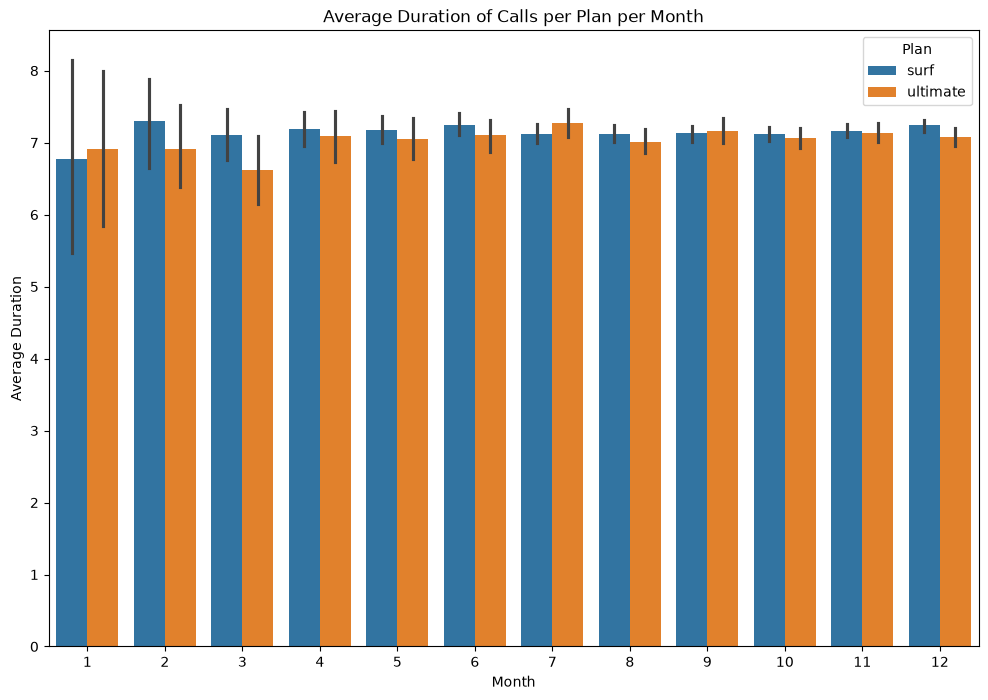

In [53]:
plt.figure(figsize=(12,8))
sns.barplot(x='month',y='duration',hue='plan',data=call_plans)

# Add labels and a title
plt.xlabel('Month')
plt.ylabel('Average Duration')
plt.title('Average Duration of Calls per Plan per Month')

# Show the plot
plt.legend(title='Plan')
plt.show()
plt.show()

##Q#2.Compare the number of minutes users of each plan use each month. Plot a histogram.


In [54]:
# merge the users_plans with original calls dataframe to incorporate plans column
call_plans = calls.merge(users_plans,on='user_id',how='left')
# calculate average calls duration based on each plan per month
call_plans = call_plans.groupby(['plan','month'])['duration'].sum().reset_index()

call_plans

,plan,month,duration
0,surf,1,406
1,surf,2,2673
2,surf,3,7590
3,surf,4,17577
4,surf,5,30768
5,surf,6,41836
6,surf,7,54448
7,surf,8,66438
8,surf,9,80360
9,surf,10,101846


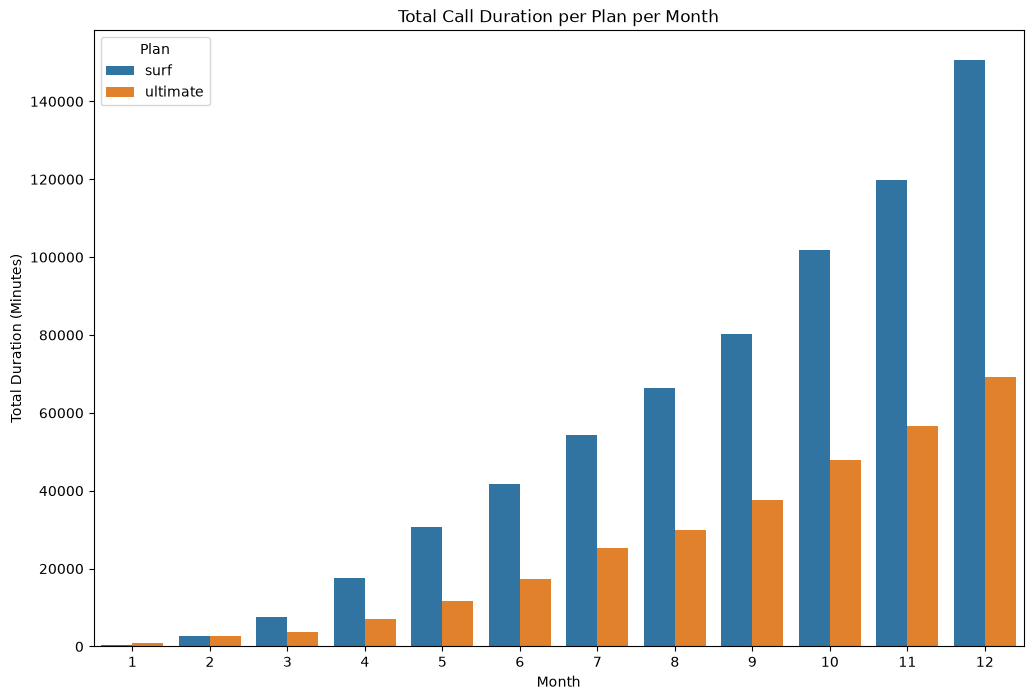

In [55]:
# Plotting the sum of call durations per plan for each month
plt.figure(figsize=(12,8))
sns.barplot(x='month', y='duration', hue='plan', data=call_plans)

# Add labels and a title
plt.xlabel('Month')
plt.ylabel('Total Duration (Minutes)')
plt.title('Total Call Duration per Plan per Month')

# Show the plot
plt.legend(title='Plan')
plt.show()

In [56]:
users['plan'].value_counts()

plan
surf        339
ultimate    161
Name: count, dtype: int64

##Q#3.Calculate and compare the mean and the variance of the monthly call duration**


In [57]:
# merge the users_plans with original calls dataframe to incorporate plans column
call_plans = calls.merge(users_plans,on='user_id',how='left')
# calculate average calls duration based on each plan per month
monthly_mean = call_plans.groupby(['plan','month'])['duration'].mean().reset_index()
monthly_mean.rename(columns={'duration':'mean_duration'},inplace=True)
monthly_var = call_plans.groupby(['plan','month'])['duration'].var().reset_index()
monthly_var.rename(columns={'duration':'var_duration'},inplace=True)

In [58]:
monthly_mean

,plan,month,mean_duration
0,surf,1,6.766667
1,surf,2,7.303279
2,surf,3,7.106742
3,surf,4,7.191899
4,surf,5,7.173700
5,surf,6,7.251863
6,surf,7,7.124836
7,surf,8,7.124718
8,surf,9,7.128537
9,surf,10,7.120604


In [59]:
monthly_var

,plan,month,var_duration
0,surf,1,28.995480
1,surf,2,36.381743
2,surf,3,33.656824
3,surf,4,34.754400
4,surf,5,35.962592
5,surf,6,36.481110
6,surf,7,34.794517
7,surf,8,35.277344
8,surf,9,36.022955
9,surf,10,35.133615


In [60]:
mean_and_var_call_df = monthly_mean.merge(monthly_var, on=['plan', 'month'], how='left')
mean_and_var_call_df

,plan,month,mean_duration,var_duration
0,surf,1,6.766667,28.995480
1,surf,2,7.303279,36.381743
2,surf,3,7.106742,33.656824
3,surf,4,7.191899,34.754400
4,surf,5,7.173700,35.962592
5,surf,6,7.251863,36.481110
6,surf,7,7.124836,34.794517
7,surf,8,7.124718,35.277344
8,surf,9,7.128537,36.022955
9,surf,10,7.120604,35.133615


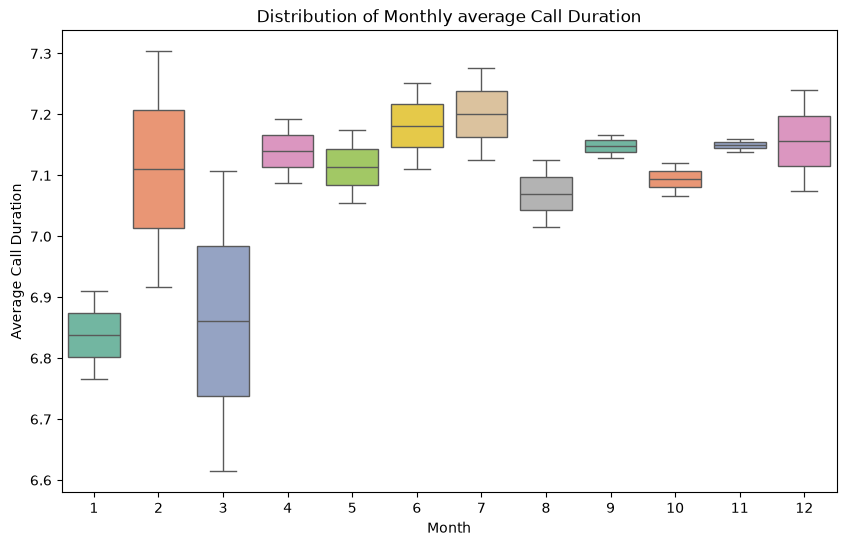

In [61]:
# Create a boxplot to visualize the distribution of monthly call duration
plt.figure(figsize=(10, 6))
sns.boxplot(x='month', y='mean_duration', data=mean_and_var_call_df, palette='Set2')

# Add labels and a title
plt.xlabel('Month')
plt.ylabel('Average Call Duration')
plt.title('Distribution of Monthly average Call Duration')

# Show the plot
plt.show()

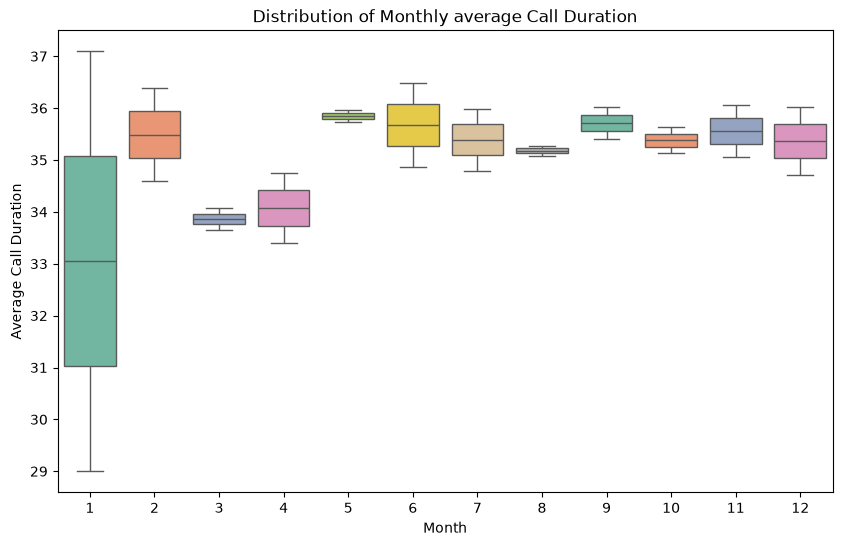

In [62]:
# Create a boxplot to visualize the distribution of monthly call duration
plt.figure(figsize=(10, 6))
sns.boxplot(x='month', y='var_duration', data=mean_and_var_call_df, palette='Set2')

# Add labels and a title
plt.xlabel('Month')
plt.ylabel('Average Call Duration')
plt.title('Distribution of Monthly average Call Duration')

# Show the plot
plt.show()

#Messages

##Q#4.Compare the number of messages users of each plan tend to send each month**


In [63]:
messages

,id,user_id,message_date,month,message_day_of_week
0,1000_125,1000,2018-12-27,12,Thursday
1,1000_160,1000,2018-12-31,12,Monday
2,1000_223,1000,2018-12-31,12,Monday
3,1000_251,1000,2018-12-27,12,Thursday
4,1000_255,1000,2018-12-26,12,Wednesday
...,...,...,...,...,...
76046,1497_526,1497,2018-12-24,12,Monday
76047,1497_536,1497,2018-12-24,12,Monday
76048,1497_547,1497,2018-12-31,12,Monday
76049,1497_558,1497,2018-12-24,12,Monday


In [64]:
# merge the users_plans with original calls dataframe to incorporate plans column
messgae_plans = messages.merge(users_plans,on='user_id',how='left')
# calculate average calls duration based on each plan per month
messgae_plans = messgae_plans.groupby(['plan','month'])['id'].count().reset_index()
messgae_plans.rename(columns={'id':'message_count'},inplace=True)

messgae_plans

,plan,month,message_count
0,surf,1,21
1,surf,2,108
2,surf,3,351
3,surf,4,870
4,surf,5,1849
5,surf,6,2454
6,surf,7,3271
7,surf,8,4662
8,surf,9,5968
9,surf,10,8020


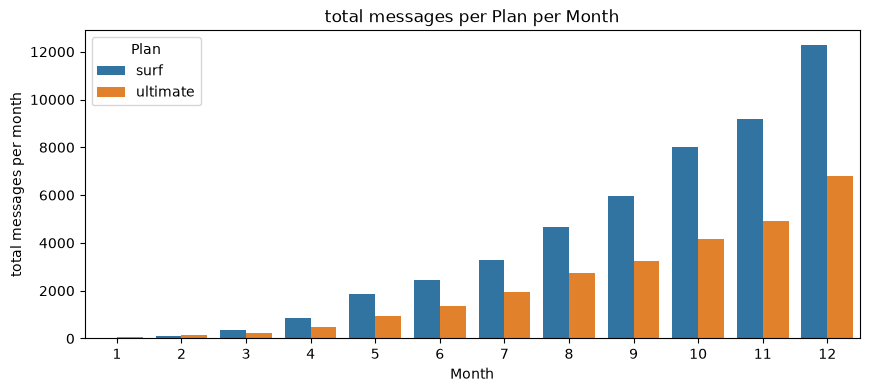

In [65]:
plt.figure(figsize=(10,4))
sns.barplot(x='month',y='message_count',hue='plan',data=messgae_plans)

# Add labels and a title
plt.xlabel('Month')
plt.ylabel('total messages per month')
plt.title('total messages per Plan per Month')

# Show the plot
plt.legend(title='Plan')
plt.show()

# Internet

##Q#1.Compare the amount of internet traffic consumed by users per plan per month

In [66]:
# Merge the two DataFrames on 'user_id'
internet_plan = internet.merge(users_plans, on='user_id', how='left')
# Convert 'mb_used' to gigabytes (GB)
internet_plan['gb_used'] = internet_plan['mb_used'] / 1024
internet_plan = internet_plan.groupby(['plan','month'])['gb_used'].sum().reset_index()
internet_plan.rename(columns={'gb_used':'total_gb_used'},inplace=True)
internet_plan

,plan,month,total_gb_used
0,surf,1,9.521211
1,surf,2,107.040615
2,surf,3,299.751094
3,surf,4,585.166162
4,surf,5,1047.948564
5,surf,6,1449.461260
6,surf,7,1983.218428
7,surf,8,2657.073906
8,surf,9,3143.298506
9,surf,10,4006.627354


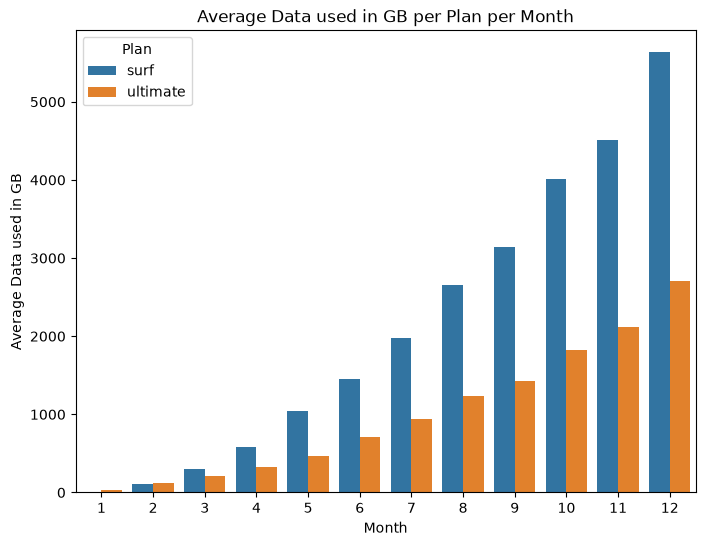

In [67]:
plt.figure(figsize=(8,6))
sns.barplot(x='month',y='total_gb_used',hue='plan',data=internet_plan)

# Add labels and a title
plt.xlabel('Month')
plt.ylabel('Average Data used in GB')
plt.title('Average Data used in GB per Plan per Month')

# Show the plot
plt.legend(title='Plan')
plt.show()

In [68]:
# Merge the two DataFrames on 'user_id'
internet_plan = internet.merge(users_plans, on='user_id', how='left')
# Convert 'mb_used' to gigabytes (GB)
internet_plan['gb_used'] = internet_plan['mb_used'] / 1024
internet_plan = internet_plan.groupby(['plan'])['gb_used'].sum().reset_index()
internet_plan.rename(columns={'gb_used':'total_gb_used'},inplace=True)
internet_plan

,plan,total_gb_used
0,surf,25435.722588
1,ultimate,12104.085723


<Axes: xlabel='plan', ylabel='total_gb_used'>

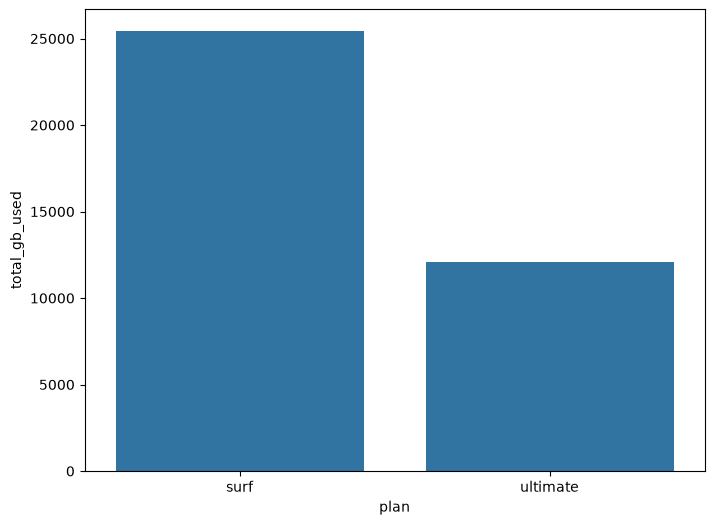

In [69]:
plt.figure(figsize=(8,6))
sns.barplot(x='plan',y='total_gb_used',data=internet_plan)

In [70]:
# Merge the two DataFrames on 'user_id'
internet_plan = internet.merge(users_plans, on='user_id', how='left')
internet_plan = internet_plan.groupby(['plan'])['mb_used'].mean().reset_index()
internet_plan.rename(columns={'mb_used':'average_mb_used'},inplace=True)
internet_plan

,plan,average_mb_used
0,surf,363.844606
1,ultimate,372.892800


<Axes: xlabel='plan', ylabel='average_mb_used'>

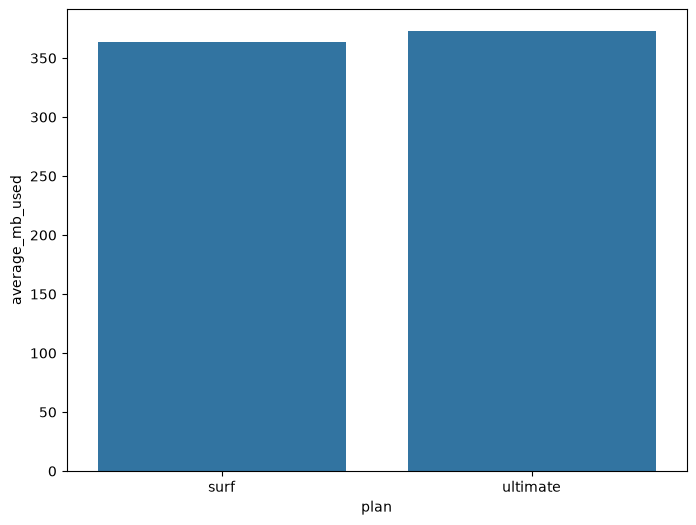

In [71]:
plt.figure(figsize=(8,6))
sns.barplot(x='plan',y='average_mb_used',data=internet_plan)

**Comparing plans per customer.** The totals above mostly reflect that Surf has about twice as many customers as
Ultimate. Comparing the average customer-month shows how each plan's customers actually behave:

In [72]:
per_customer = merged_data.assign(gb_used=np.ceil(merged_data['mb_used'] / 1024))
per_customer.groupby('plan')[['total_duration', 'message_count', 'gb_used']].agg(['mean', 'median']).round(1)

total_duration        message_count        gb_used       
                   mean median          mean median    mean median
plan                                                              
surf              428.7  425.0          31.2   24.0    16.7   17.0
ultimate          430.4  424.0          37.6   30.0    17.3   17.0

- Per customer and month, both plans use almost exactly the same: about 430 minutes and 17 GB. Ultimate customers send
  slightly more texts (about 38 against 31). The large gaps in the totals come from the number of customers on each plan.

# Revenue

##Q#1.statistically describe the revenue between the plans

In [73]:
merged_data.groupby('plan')['monthly_revenue'].describe()

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
surf,1573.0,60.706408,55.388042,20.0,20.0,40.36,80.36,590.37
ultimate,720.0,72.313889,11.395108,70.0,70.0,70.00,70.00,182.00


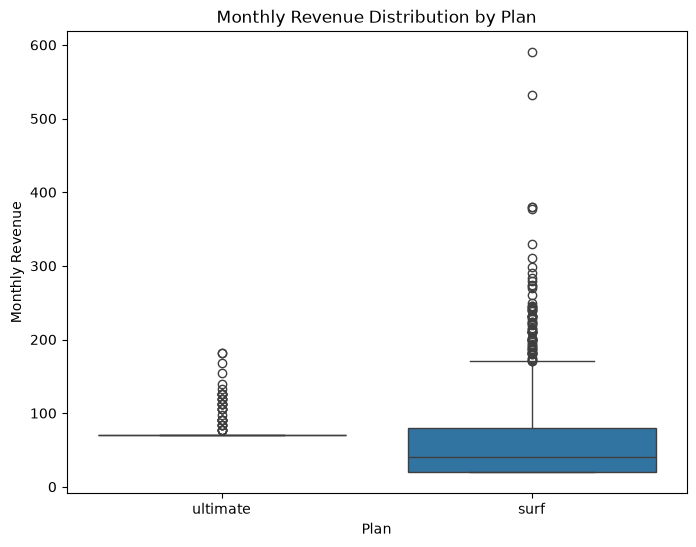

In [74]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='plan', y='monthly_revenue', data=merged_data)
plt.title('Monthly Revenue Distribution by Plan')
plt.xlabel('Plan')
plt.ylabel('Monthly Revenue')
plt.show()

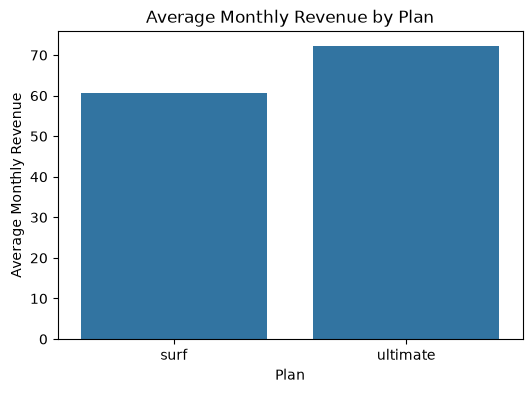

In [75]:
# Group your DataFrame by the "plan" column and calculate the mean revenue for each plan
plan_revenue_mean = merged_data.groupby('plan')['monthly_revenue'].mean().reset_index()

# Create a bar plot
plt.figure(figsize=(6,4))
sns.barplot(x='plan', y='monthly_revenue', data=plan_revenue_mean)
plt.title('Average Monthly Revenue by Plan')
plt.xlabel('Plan')
plt.ylabel('Average Monthly Revenue')
plt.show()

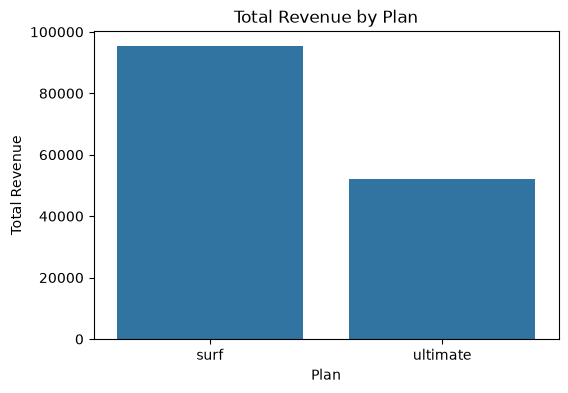

In [76]:
# Group your DataFrame by the "plan" column and calculate the mean revenue for each plan
plan_revenue_mean = merged_data.groupby('plan')['monthly_revenue'].sum().reset_index()

# Create a bar plot
plt.figure(figsize=(6,4))
sns.barplot(x='plan', y='monthly_revenue', data=plan_revenue_mean)
plt.title('Total Revenue by Plan')
plt.xlabel('Plan')
plt.ylabel('Total Revenue')
plt.show()

#Hypotheis Testing

##1. Test the hypothesis that the average revenue from users of the Ultimate and Surf calling plans differs.

**Null Hypothesis (H0):**

The average revenue from users of the Ultimate and Surf calling plans is equal.

**Alternative Hypothesis (H1):**

The average revenue from users of the Ultimate and Surf calling plans is not equal.

**Statistic model**

To test this hypothesis, we can use a two-sample t-test because we are comparing the means of two independent groups (Ultimate and Surf plans) to determine if they are statistically different from each other.

**Significance Level (Alpha)**:

We need to choose a significance level, denoted as **α, which represents the probability of making a Type I error**. A common choice for α is 0.05, which corresponds to a 5% significance level. This means that we are willing to accept a 5% chance of making a Type I error (rejecting the null hypothesis when it's actually true).

In [77]:
ultimate_revenue = merged_data[merged_data['plan'] == 'ultimate']['monthly_revenue']
surf_revenue = merged_data[merged_data['plan'] == 'surf']['monthly_revenue']

# Perform a two-sample t-test
t_statistic, p_value = stats.ttest_ind(ultimate_revenue, surf_revenue , equal_var=False)

alpha = 0.05

# Print the results
print("T-statistic:", t_statistic)
print("P-value:", p_value)

if p_value < alpha:
    print("Reject the null hypothesis. There is a significant difference in average revenue between Ultimate and Surf plan users.")
else:
    print("Fail to reject the null hypothesis. There is no significant difference in average revenue between Ultimate and Surf plan users.")

T-statistic: 7.952094891333888
P-value: 3.170390548113581e-15
Reject the null hypothesis. There is a significant difference in average revenue between Ultimate and Surf plan users.


##2. Test the hypothesis that the average revenue from users in the NY-NJ area is different from that of the users from the other regions

In [78]:
# Merge the data on 'user_id' to get user information along with monthly revenue
merged_data = merged_data.merge(users[['user_id', 'state']], on='user_id', how='left')

# Separate revenue data for NY-NJ area and other regions
ny_nj_revenue = merged_data[merged_data['state'] == ' NY-NJ-PA MSA']['monthly_revenue']
other_regions_revenue = merged_data[merged_data['state'] != ' NY-NJ-PA MSA']['monthly_revenue']

# Perform the two-sample t-test
t_statistic, p_value = stats.ttest_ind(ny_nj_revenue, other_regions_revenue, equal_var=False)

alpha = 0.05

print(f'Test Statistic: {t_statistic}')
print(f'P-value: {p_value}')

if p_value < alpha:
    print("Reject the null hypothesis. There is a significant difference in average revenue between NY-NJ area users and users from other regions.")
else:
    print("Fail to reject the null hypothesis. There is no significant difference in average revenue between NY-NJ area users and users from other regions.")


Test Statistic: -2.1309454999502133
P-value: 0.03352561588530015
Reject the null hypothesis. There is a significant difference in average revenue between NY-NJ area users and users from other regions.


**Checking the regional result with each customer counted once.** A customer contributes up to 12 monthly bills, so
the test above treats one person as up to 12 independent observations. Repeating the test on each customer's average
bill:

In [79]:
per_user = merged_data.groupby(['user_id', 'state'], as_index=False)['monthly_revenue'].mean()
ny_nj_users = per_user[per_user['state'] == ' NY-NJ-PA MSA']['monthly_revenue']
other_users = per_user[per_user['state'] != ' NY-NJ-PA MSA']['monthly_revenue']
t_statistic, p_value = stats.ttest_ind(ny_nj_users, other_users, equal_var=False)
print(f'Customers: NY-NJ {len(ny_nj_users)}, other regions {len(other_users)}')
print(f'Test Statistic: {t_statistic}')
print(f'P-value: {p_value}')
if p_value < alpha:
    print("Reject the null hypothesis at the customer level.")
else:
    print("Fail to reject the null hypothesis at the customer level: no reliable regional difference.")

Customers: NY-NJ 79, other regions 411
Test Statistic: -0.7729762700323378
P-value: 0.44104821081481743
Fail to reject the null hypothesis at the customer level: no reliable regional difference.


In [80]:
# The same check for the plan comparison
per_user_plan = merged_data.groupby(['user_id', 'plan'], as_index=False)['monthly_revenue'].mean()
print(stats.ttest_ind(per_user_plan[per_user_plan['plan'] == 'ultimate']['monthly_revenue'],
                      per_user_plan[per_user_plan['plan'] == 'surf']['monthly_revenue'], equal_var=False))

TtestResult(statistic=np.float64(5.540694181472272), pvalue=np.float64(5.719435130362412e-08), df=np.float64(371.16937971494684))


- The **plan difference is robust**: it stays highly significant when each customer is counted once.
- The **regional difference is not**: it is significant only when every month counts as a separate observation; with
  each customer counted once the p-value is far above 0.05.

#Conclusion
1. **Usage per customer is the same on both plans**
   - Per customer and month, Surf and Ultimate customers use about the same call minutes (about 430) and data (about 17 GB); Ultimate customers send slightly more texts (about 38 against 31).
   - Monthly means and variances of call duration barely change from month to month. Averages are lower early in the year mainly because a customer's first month is a partial month.

2. **Totals differ because of the number of customers**
   - Surf shows more total minutes, texts and data in every month because it has 339 customers against Ultimate's 161, not because its customers use more.

3. **Message and data trends**
   - Messages and data grow from January to December as the customer base grows.
   - Low data-usage sessions are more frequent than high-usage sessions on both plans.

4. **Revenue by plan** (with Megaline's billing rules: calls rounded up per call, monthly data rounded up to whole GB)
   - The average monthly bill is \$72.31 on Ultimate and \$60.71 on Surf. Ultimate revenue is stable (almost everyone pays \$70); Surf varies widely (median \$40.36), driven by extra data.
   - Surf brings in more total revenue because it has more customers.

5. **Hypothesis tests**
   - Average revenue differs significantly between Ultimate and Surf (p < 0.001), whether each month or each customer is counted once.
   - The NY-NJ area looks significantly different when every month is counted (p ≈ 0.03), but not when each customer is counted once (p ≈ 0.44). There is no reliable evidence that the region pays differently.